# M04-1 | PTQ 的 BN 折疊：發生在哪一步、weight 怎麼改寫

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m04_conv_bn_folding/01_bn_folding_trace.ipynb)

舊的 eager／FX 量化會把 Conv + BN + ReLU 換成一個 `ConvBnReLU2d` 模組。PT2E 沒有這種模組：
圖上的 `conv2d`、`batch_norm`、`relu` 一開始就是三個獨立的 node。這本 notebook 沿著 PTQ 流程看 BN 怎麼消失：

- **A.** BN 在哪一步消失：export → prepare → convert。
- **B.** 折疊本身無損：折完、還沒量化時，輸出和原模型一樣。
- **C.** weight 怎麼被改寫，bias 怎麼憑空出現。
- **D.** 折完之後：conv_bn_relu 和 conv_relu 一樣；conv 與 relu 之間多一個量化點，convert 之後長什麼樣。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m04_conv_bn_folding")

In [1]:
import copy

import torch

from common.data import calibration_batches
from common.graph_utils import observer_nodes
from common.models import ConvBnReLU, example_inputs, get_model
from common.pt2e import (
    ANNOTATION_KEY,
    Quantizer,
    annotate_input_qspec_map,
    annotate_output_qspec,
    convert_pt2e,
    export_module,
    get_xnnpack_quantizer,
    prepare_pt2e,
    quiet,
)
from common.qspecs import act_spec, weight_spec
from common.viz import draw, draw_stages

quiet()
_ = torch.manual_seed(0)
CONV2D = torch.ops.aten.conv2d.default
RELU = torch.ops.aten.relu.default


def calibrate(prepared):
    with torch.no_grad():
        for batch in calibration_batches(64):
            prepared(*batch)

模型是一個 conv（沒有 bias）+ BN + relu。BN 剛建立時 running mean = 0、running var = 1，折進去等於什麼都沒做，
所以先用 train 模式跑幾個 batch，讓它有真實的 running stats，折疊前後的 weight 才看得出差別：

In [2]:
model = ConvBnReLU(3, 8).train()
with torch.no_grad():
    for _ in range(5):
        model(torch.randn(16, 3, 16, 16) * 2 + 1)
model.eval()

gm = export_module(model, example_inputs())
quantizer, _ = get_xnnpack_quantizer(is_per_channel=True)

## A. BN 在哪一步消失

對同一張 export 的圖做 `prepare_pt2e`、校準、`convert_pt2e`。第一個 row 是 export 與 prepare，第二個 row 是 convert：

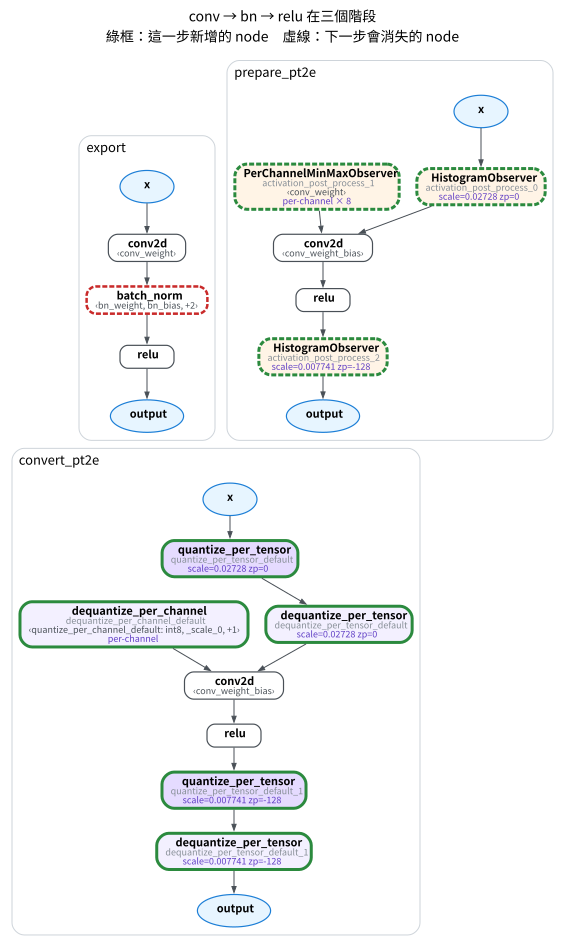

In [3]:
prepared = prepare_pt2e(copy.deepcopy(gm), quantizer)
calibrate(prepared)
converted = convert_pt2e(copy.deepcopy(prepared))
draw_stages([(gm, "export"), (prepared, "prepare_pt2e"), (converted, "convert_pt2e")], title="conv → bn → relu 在三個階段")

In [4]:
def has_bn(g):
    return any("batch_norm" in str(n.target) for n in g.graph.nodes)


print("圖上有 batch_norm？ export:", has_bn(gm), " prepare:", has_bn(prepared), " convert:", has_bn(converted))
assert has_bn(gm) and not has_bn(prepared) and not has_bn(converted)

圖上有 batch_norm？ export: True  prepare: False  convert: False


- `batch_norm` 在 export 時還在，`prepare_pt2e` 之後就沒了；convert 不再碰 BN。
- 圖上沒有任何「fused 模組」：`conv2d` 和 `relu` 仍是兩個獨立的 node。

`prepare_pt2e` 在呼叫 Quantizer 之前，先把 BN 折進前面的 conv（M03 概覽列過它的步驟），所以 Quantizer 看到的圖已經沒有 BN。

## B. 折疊本身無損

重新 prepare 一份、不校準：observer 只觀察、不改數值，所以這張圖和「只折了 BN 的 fp32 圖」等價。和原模型比：

In [5]:
fresh = prepare_pt2e(copy.deepcopy(gm), quantizer)
x = torch.randn(8, 3, 16, 16)
with torch.no_grad():
    diff = float((model(x) - fresh(x)).abs().max())
print(f"原模型（conv + bn + relu） vs 折完 BN 的圖：max|diff| = {diff:.2e}")
assert diff < 1e-5

原模型（conv + bn + relu） vs 折完 BN 的圖：max|diff| = 4.77e-07


差異只有浮點誤差的量級：折疊只是代數重排，量化誤差都是之後才加進來的。

## C. weight 怎麼被改寫

eval 模式的 BN 對每個 channel 做 $\mathrm{BN}(y) = \gamma \dfrac{y - \mu}{\sqrt{\sigma^2 + \varepsilon}} + \beta$，
其中 $\mu$、$\sigma^2$ 是 running mean／var，$\gamma$、$\beta$ 是 BN 的 weight／bias。
conv 的輸出 $y = W * x + b$ 代進去，整理成另一個 conv：

$$
W_{\text{fold}} = W \cdot \frac{\gamma}{\sqrt{\sigma^2+\varepsilon}} \tag{1}
$$

$$
b_{\text{fold}} = \beta + (b - \mu)\,\frac{\gamma}{\sqrt{\sigma^2+\varepsilon}} \tag{2}
$$

式 (1) 的乘法是逐 output channel 的：第 $k$ 個 output channel 的 weight 全部乘上同一個 $\gamma_k / \sqrt{\sigma_k^2+\varepsilon}$。
這個模型的 conv 沒有 bias，$b = 0$。先看 prepare 前後，圖上用到哪些參數（`get_attr` node）：

In [6]:
print("export： ", [n.target for n in gm.graph.nodes if n.op == "get_attr"])
print("prepare：", [n.target for n in prepared.graph.nodes if n.op == "get_attr"])

export：  ['conv.weight', 'bn.weight', 'bn.bias', 'bn.running_mean', 'bn.running_var', 'bn.num_batches_tracked']
prepare： ['conv.weight', 'conv.weight_bias']


BN 的四個參數都不見了，多了一個 `conv.weight_bias`：原本沒有 bias 的 conv，折完之後需要式 (2) 的 bias，就長出這個新常數。
`conv.weight` 的名字沒變，值已經換成式 (1)。用 BN 的參數手算，和 torchao 折出來的比：

In [7]:
bn = model.bn
assert bn.running_mean is not None and bn.running_var is not None
k = bn.weight / torch.sqrt(bn.running_var + bn.eps)  # 每個 output channel 一個 γ/√(σ²+ε)
w_fold = model.conv.weight * k.reshape(-1, 1, 1, 1)  # 式 (1)
b_fold = bn.bias - bn.running_mean * k  # 式 (2)，b = 0

w_torchao = prepared.get_parameter("conv.weight")
b_torchao = getattr(prepared.get_submodule("conv"), "weight_bias")  # 折 BN 時新加的 bias
print(f"weight 被改寫了多少：max|W_fold - W| = {float((w_torchao - model.conv.weight).abs().max()):.3f}")
print("式 (1) 與 torchao 的 weight 相同？", torch.allclose(w_torchao, w_fold, atol=1e-6))
print("式 (2) 與 torchao 的 bias 相同？  ", torch.allclose(b_torchao, b_fold, atol=1e-6))
assert torch.allclose(w_torchao, w_fold, atol=1e-6) and torch.allclose(b_torchao, b_fold, atol=1e-6)

weight 被改寫了多少：max|W_fold - W| = 0.016
式 (1) 與 torchao 的 weight 相同？ True
式 (2) 與 torchao 的 bias 相同？   True


所以 prepare 之後被量化的 weight，已經是 conv 和 BN 合體後的 weight，不是原本的 `conv.weight`。

每個 output channel 乘上不同的 $\gamma_k / \sqrt{\sigma_k^2+\varepsilon}$，折完後各 channel 的值域會變得不一樣大。
推論（這裡沒有量測誤差差距）：這是 per-channel weight 量化在有 BN 的模型上特別重要的原因之一。

QAT 不能在 prepare 時這樣折，因為訓練中 BN 還要用 batch 統計，見 M04-2。

## D. 折完之後：conv 與 relu 之間的量化點

BN 折掉之後，conv_bn_relu 在圖上就和 conv_relu 一樣。用 XNNPACKQuantizer 比兩個模型的 activation observer 夾在哪兩個 node 之間：

In [8]:
def activation_sites(prepared):
    """每個 activation observer 寫成「上游 → 下游」；weight 的 observer（輸入是 get_attr）略過。"""
    return [f"{n.args[0].name} → {', '.join(u.name for u in n.users)}"
            for n, _ in observer_nodes(prepared) if n.args[0].op != "get_attr"]


sites = {}
for name in ("conv_relu", "conv_bn_relu"):
    p = prepare_pt2e(export_module(get_model(name).eval(), example_inputs()), get_xnnpack_quantizer(is_per_channel=True)[0])
    sites[name] = activation_sites(p)
    print(f"{name:<13}", sites[name])
assert sites["conv_relu"] == sites["conv_bn_relu"]

conv_relu     ['x → conv2d', 'relu → output']
conv_bn_relu  ['x → conv2d', 'relu → output']


兩者完全相同：輸入一個、relu 的輸出一個，conv 與 relu 之間沒有。這是 XNNPACKQuantizer 把輸出標籤貼在 relu、不貼在 conv 的結果（M03-2 A），
也就是 PT2E 裡 conv + relu 的「融合」。

M03-3、M03-6 在 prepare 的圖上看過「conv 的輸出也貼標籤」會多一個 observer。這裡看它在 **convert 之後**長什麼樣。
兩個 Quantizer 只差一件事：`fuse=False` 時，conv 的輸出也貼標籤。

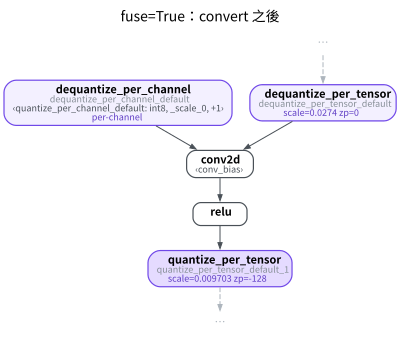

In [9]:
class ConvReluQuantizer(Quantizer):
    def __init__(self, fuse: bool):
        self.fuse = fuse

    def annotate(self, model):
        for conv in [n for n in model.graph.nodes if n.op == "call_function" and n.target == CONV2D]:
            annotate_input_qspec_map(conv, conv.args[0], act_spec())
            annotate_input_qspec_map(conv, conv.args[1], weight_spec())
            relu = next(u for u in conv.users if u.target == RELU)
            annotate_output_qspec(relu, act_spec())
            if not self.fuse:
                annotate_output_qspec(conv, act_spec())  # 多貼這一張：conv 的輸出也量化
            for node in (conv, relu):
                node.meta[ANNOTATION_KEY]._annotated = True
        return model

    def validate(self, model):
        pass


gm_cr = export_module(get_model("conv_relu").eval(), example_inputs())
results = {}
for fuse in (True, False):
    p = prepare_pt2e(copy.deepcopy(gm_cr), ConvReluQuantizer(fuse))
    calibrate(p)
    results[fuse] = convert_pt2e(p)
draw(results[True], focus=["conv2d", "relu"], title="fuse=True：convert 之後")

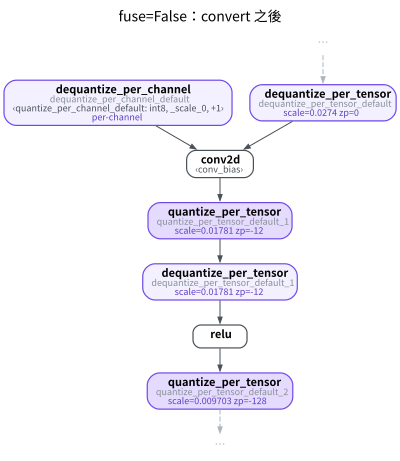

In [10]:
draw(results[False], focus=["conv2d", "relu"], title="fuse=False：convert 之後")

In [11]:
def between_conv_and_relu(g):
    """relu 的輸入往回走到 conv 為止，經過的 node。"""
    relu = next(n for n in g.graph.nodes if n.target == RELU)
    steps, src = [], relu.args[0]
    while src.target != CONV2D:
        steps.append(str(src.target).split(".")[1])
        src = src.args[0]
    return steps[::-1]


print("fuse=True： conv2d 與 relu 之間：", between_conv_and_relu(results[True]))
print("fuse=False：conv2d 與 relu 之間：", between_conv_and_relu(results[False]))
assert between_conv_and_relu(results[True]) == []
assert between_conv_and_relu(results[False]) == ["quantize_per_tensor", "dequantize_per_tensor"]

fuse=True： conv2d 與 relu 之間： []
fuse=False：conv2d 與 relu 之間： ['quantize_per_tensor', 'dequantize_per_tensor']


- **fuse=True**：conv2d 直接接 relu，中間是 fp32 的 tensor。整段是 dq → conv2d → relu → q。
- **fuse=False**：conv2d 與 relu 之間多了一對 quantize → dequantize，變成 dq → conv2d → q → dq → relu → q。

M02-3 C 看過，後端 lowering 是在 Q/DQ 圖上比對「dq → op → q」這類 pattern，再換成整數 kernel。
conv + relu 的 kernel 要求 conv 與 relu 相鄰；中間被一對 q/dq 隔開，就只能分成 conv、relu 兩個 kernel，conv 的輸出先存成 int8 再讀回來。
推論（這裡沒有逐 kernel 對照）：多一個量化點也多一次捨入，而且 conv 輸出的範圍包含 relu 會砍掉的負值，浪費一部分整數範圍。

## 小結

- PTQ 的 BN 在 `prepare_pt2e` 一開始就折進 conv，早於 Quantizer 的 `annotate`；折疊無損。
- 折完的 weight 是式 (1)，bias 是式 (2)；原本沒有 bias 的 conv 會長出 `weight_bias`。
- PT2E 的「融合」= BN 折疊 + conv 與 relu 之間不放量化點；多放一個，convert 之後就多一對 q/dq，後端的 pattern 對不上。